# SemEval 2025 Task 9 – analýza dát a chybová analýza (1. etapa, osoba 2)

Tento notebook dopĺňa `baseline_food_hazard.ipynb`. Modely sám netrénuje: načíta **predikcie, ktoré uložil baseline notebook** (`results/predikcie_test.csv`, modely SVM a LR so vstupom titulok + text a `class_weight="balanced"`). Chybová analýza preto vždy rozoberá presne tie isté predikcie, z ktorých je tabuľka výsledkov v správe.

**Poradie spúšťania:** najprv `baseline_food_hazard.ipynb`, potom tento notebook.

**Obsah:**
1. analýza dát (EDA): rozdelenie tried, dlhý chvost, krajiny a roky, dĺžky textov, duplicity a prekryv množín, nič nehovoriace titulky, overenie čísel z tabuľky v sekcii 4 správy,
2. načítanie predikcií z baseline a kontrola, že sedia čísla zo správy,
3. chybová analýza: matica zámen, najčastejšie zamieňané dvojice, ukážky chýb na ručný komentár, výkon podľa početnosti triedy, nevidené triedy, chyby v rámci správnej kategórie,
4. bootstrap 95 % intervaly spoľahlivosti pre ST1 a ST2 a rozdiel SVM oproti LR.

Testovaciu množinu tu **neladíme**, iba analyzujeme predikcie. Beží na CPU asi 1 minútu. Obrázky sa ukladajú do `results/figures/`, tabuľky do `results/` (v koreni repozitára).

## 0. Importy a nastavenia

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.exceptions import UndefinedMetricWarning

# pri macro-F1 sklearn upozorňuje na triedy, ktoré model nikdy nepredikoval (ich F1 = 0); potláčame len toto upozornenie
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
SEED = 42
np.random.seed(SEED)

# výstupy idú do results/ v koreni repozitára (notebook leží v notebooks/)
KOREN = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
VYSLEDKY = os.path.join(KOREN, "results")
OBRAZKY = os.path.join(VYSLEDKY, "figures")
os.makedirs(OBRAZKY, exist_ok=True)
pd.set_option("display.max_colwidth", 80)
LABELY = ["hazard-category", "product-category", "hazard", "product"]

## 1. Načítanie dát
Rovnako ako v baseline: CSV pri notebooku, v `data/` alebo v `../data/` (štruktúra repozitára), inak stiahnutie z oficiálneho repozitára úlohy. Vypíšeme, odkiaľ sa dáta načítali.

In [2]:
URL = "https://raw.githubusercontent.com/food-hazard-detection-semeval-2025/food-hazard-detection-semeval-2025.github.io/main/data/"

def nacitaj(nazov):
    subor = f"{nazov}.csv"
    for cesta in [subor, os.path.join("data", subor), os.path.join("..", "data", subor)]:
        if os.path.exists(cesta):      # pri notebooku, v data/ alebo v ../data/
            print(f"{nazov}: {cesta}")
            return pd.read_csv(cesta)
    print(f"{nazov}: stiahnuté z {URL}")
    return pd.read_csv(URL + subor)

train = nacitaj("incidents_train")
valid = nacitaj("incidents_valid")
test  = nacitaj("incidents_test")
print("train:", train.shape, " valid:", valid.shape, " test:", test.shape)
print("chýbajúce hodnoty spolu:", int(train.isna().sum().sum() + valid.isna().sum().sum() + test.isna().sum().sum()))

incidents_train: ../data/incidents_train.csv
incidents_valid: ../data/incidents_valid.csv
incidents_test: ../data/incidents_test.csv


train: (5082, 11)  valid: (565, 11)  test: (997, 11)
chýbajúce hodnoty spolu: 0


## 2. Analýza dát (EDA)

### 2.1 Overenie čísel z tabuľky v sekcii 4 správy
Pre každý label: počet tried v train, najpočetnejšia a najmenej početná trieda, počet tried s jediným príkladom a s menej ako 5 príkladmi.

In [3]:
riadky = []
for lab in LABELY:
    pocty = train[lab].value_counts()
    najmenej = pocty[pocty == pocty.min()]
    riadky.append({
        "label": lab,
        "tried v train": len(pocty),
        "najpočetnejšia": f"{pocty.index[0]} ({pocty.iloc[0]})",
        "najmenej príkladov": pocty.min(),
        "koľko tried má toto minimum": len(najmenej),
        "príklad takej triedy": najmenej.index[0],
        "tried s 1 príkladom": int((pocty == 1).sum()),
        "tried s < 5 príkladmi": int((pocty < 5).sum()),
    })
overenie = pd.DataFrame(riadky)
overenie

,label,tried v train,najpočetnejšia,najmenej príkladov,koľko tried má toto minimum,príklad takej triedy,tried s 1 príkladom,tried s < 5 príkladmi
0,hazard-category,10,allergens (1854),3,1,migration,0,1
1,product-category,22,"meat, egg and dairy products (1434)",5,1,sugars and syrups,0,0
2,hazard,128,listeria monocytogenes (665),3,27,sulfamethazine unauthorised,0,42
3,product,1022,ice cream (185),1,458,ham slices,458,777


In [4]:
print("product-category, 5 najmenších tried:")
print(train["product-category"].value_counts().tail(5).to_string())
hc = train["hazard-category"].value_counts()
print(f"\nhazard-category: 2 najväčšie triedy = {hc.iloc[:2].sum() / len(train):.1%} dát, 4 najmenšie = {hc.iloc[-4:].sum() / len(train):.1%}")
print(f"model 'vždy allergens' by mal accuracy na train {hc.iloc[0] / len(train):.1%}, na teste {(test['hazard-category'] == hc.index[0]).mean():.1%}")

product-category, 5 najmenších tried:
product-category
food additives and flavourings    8
honey and royal jelly             8
food contact materials            7
feed materials                    6
sugars and syrups                 5

hazard-category: 2 najväčšie triedy = 70.7% dát, 4 najmenšie = 2.6%
model 'vždy allergens' by mal accuracy na train 36.5%, na teste 36.6%


### 2.2 Rozdelenie `product-category` (22 tried)
Logaritmická os x, aby boli vidieť aj malé triedy.

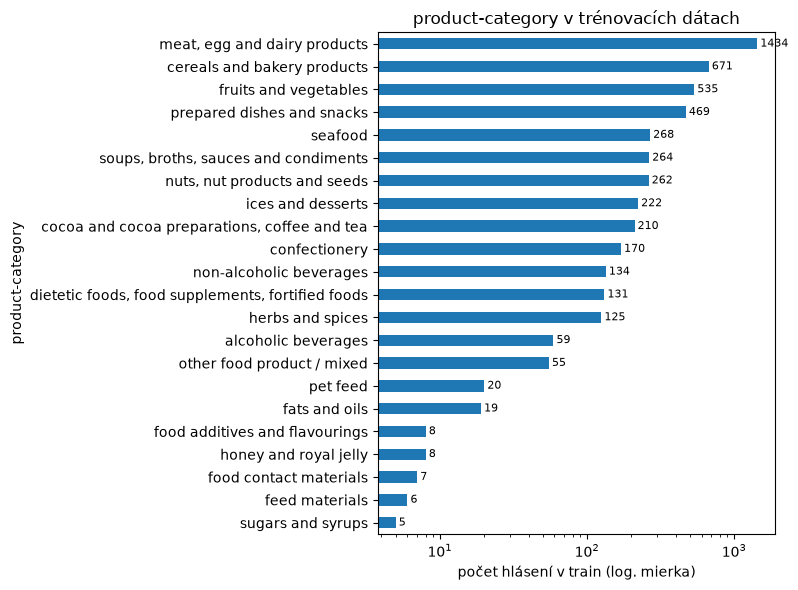

In [5]:
pocty = train["product-category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 6))
pocty.plot(kind="barh", ax=ax, logx=True)
ax.invert_yaxis()
ax.set_xlabel("počet hlásení v train (log. mierka)")
ax.set_title("product-category v trénovacích dátach")
for i, v in enumerate(pocty.values):
    ax.text(v * 1.05, i, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OBRAZKY, "product_category.png"), dpi=150); plt.show()

### 2.3 Dlhý chvost pri `hazard` a `product`
Triedy zoradíme od najpočetnejšej a vykreslíme počet príkladov podľa poradia triedy (obe osi logaritmické). Čím dlhší plochý koniec pri hodnote 1, tým viac tried má jediný príklad.

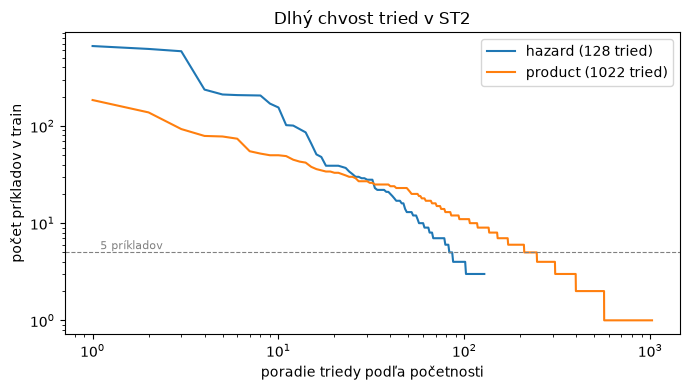

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for lab in ["hazard", "product"]:
    p = train[lab].value_counts().values
    ax.plot(np.arange(1, len(p) + 1), p, label=f"{lab} ({len(p)} tried)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(5, color="gray", ls="--", lw=0.8)
ax.text(1.1, 5.4, "5 príkladov", color="gray", fontsize=8)
ax.set_xlabel("poradie triedy podľa početnosti"); ax.set_ylabel("počet príkladov v train")
ax.set_title("Dlhý chvost tried v ST2")
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(OBRAZKY, "dlhy_chvost.png"), dpi=150); plt.show()

### 2.4 Dĺžky titulkov a textov

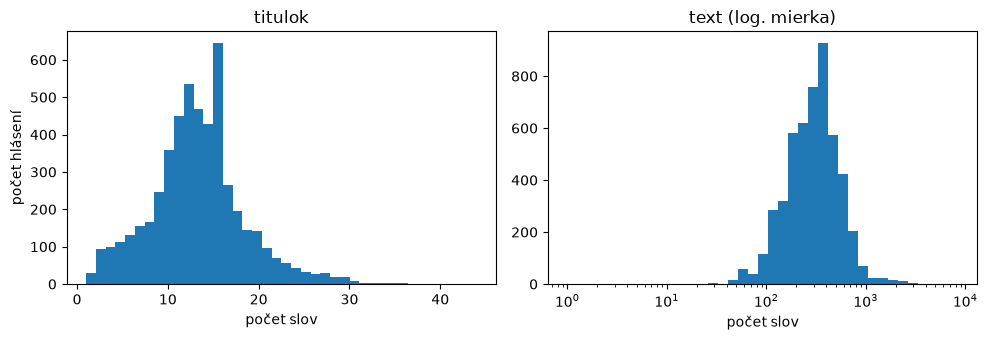

titulok: priemer 13.3, medián 13, max 44 slov
text:    priemer 353, medián 306, max 8406 slov; kratších ako 20 slov: 3


In [7]:
dl_t = train["title"].str.split().str.len()
dl_x = train["text"].str.split().str.len()
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].hist(dl_t, bins=40); axs[0].set_title("titulok"); axs[0].set_xlabel("počet slov")
axs[1].hist(dl_x, bins=np.logspace(0, np.log10(dl_x.max()), 40)); axs[1].set_xscale("log")
axs[1].set_title("text (log. mierka)"); axs[1].set_xlabel("počet slov")
axs[0].set_ylabel("počet hlásení")
plt.tight_layout(); plt.savefig(os.path.join(OBRAZKY, "dlzky.png"), dpi=150); plt.show()
print(f"titulok: priemer {dl_t.mean():.1f}, medián {dl_t.median():.0f}, max {dl_t.max()} slov")
print(f"text:    priemer {dl_x.mean():.0f}, medián {dl_x.median():.0f}, max {dl_x.max()} slov; kratších ako 20 slov: {(dl_x < 20).sum()}")

### 2.5 Krajiny a roky

In [8]:
spolu = pd.concat([train.assign(mnozina="train"), valid.assign(mnozina="valid"), test.assign(mnozina="test")], ignore_index=True)
krajiny = pd.crosstab(spolu["country"], spolu["mnozina"])[["train", "valid", "test"]]
krajiny = krajiny.sort_values("train", ascending=False)
krajiny["podiel train"] = (krajiny["train"] / len(train)).map("{:.1%}".format)
print("počet krajín:", len(krajiny))
krajiny.head(10)

počet krajín: 9


mnozina,train,valid,test,podiel train
country,,,,
us,2195,239,419,43.2%
au,921,112,173,18.1%
ca,856,94,162,16.8%
uk,687,70,146,13.5%
ie,269,28,61,5.3%
hk,92,12,19,1.8%
na,54,8,13,1.1%
sg,6,1,4,0.1%
scot,2,1,0,0.0%


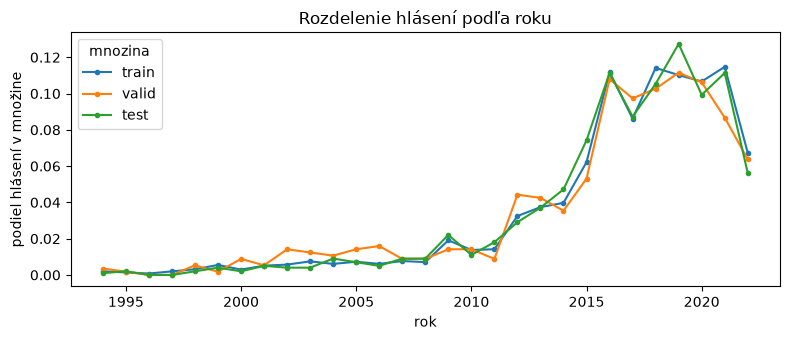

roky: 1994 – 2022


In [9]:
roky = pd.crosstab(spolu["year"], spolu["mnozina"])[["train", "valid", "test"]]
fig, ax = plt.subplots(figsize=(8, 3.5))
(roky / roky.sum()).plot(ax=ax, marker="o", ms=3)
ax.set_ylabel("podiel hlásení v množine"); ax.set_xlabel("rok")
ax.set_title("Rozdelenie hlásení podľa roku")
plt.tight_layout(); plt.savefig(os.path.join(OBRAZKY, "roky.png"), dpi=150); plt.show()
print("roky:", roky.index.min(), "–", roky.index.max())

In [10]:
# súvisí krajina s typom rizika? (podiel hazard-category v 4 najčastejších krajinách)
top4 = krajiny.index[:4]
pd.crosstab(train.loc[train.country.isin(top4), "country"],
            train.loc[train.country.isin(top4), "hazard-category"], normalize="index").round(2)

hazard-category,allergens,biological,chemical,food additives and flavourings,foreign bodies,fraud,organoleptic aspects,other hazard,packaging defect
country,,,,,,,,,
au,0.35,0.28,0.06,0.01,0.18,0.06,0.02,0.02,0.02
ca,0.32,0.47,0.04,0.00,0.11,0.01,0.02,0.01,0.01
uk,0.54,0.16,0.03,0.00,0.12,0.06,0.01,0.06,0.02
us,0.36,0.40,0.03,0.00,0.08,0.10,0.00,0.03,0.00


### 2.6 Duplicity a prekryv medzi množinami
Ak by rovnaké hlásenie bolo v train aj v teste, výsledok na teste by bol prikrášlený. Kontrolujeme zhodu titulku a zhodu celého textu.

In [11]:
def norm(s):
    return s.str.lower().str.strip()

print("V rámci train:")
print(f"  rovnaký titulok ako iné hlásenie: {norm(train.title).duplicated(keep=False).sum()} hlásení")
print(f"  úplne rovnaký titulok + text:     {(norm(train.title) + norm(train.text)).duplicated(keep=False).sum()} hlásení")

riadky = []
for meno, d in [("valid", valid), ("test", test)]:
    t_tr, x_tr = set(norm(train.title)), set(norm(train.text))
    titul = norm(d.title).isin(t_tr)
    text = norm(d.text).isin(x_tr)
    riadky.append({"množina": meno, "hlásení": len(d),
                   "titulok sa vyskytuje v train": int(titul.sum()),
                   "text sa vyskytuje v train": int(text.sum()),
                   "titulok aj text v train": int((titul & text).sum())})
pd.DataFrame(riadky)

V rámci train:
  rovnaký titulok ako iné hlásenie: 262 hlásení
  úplne rovnaký titulok + text:     58 hlásení


,množina,hlásení,titulok sa vyskytuje v train,text sa vyskytuje v train,titulok aj text v train
0,valid,565,30,6,6
1,test,997,48,7,7


In [12]:
# Keď je text testovacieho hlásenia identický s nejakým v train, majú aj rovnaké labely?
mapa = train.assign(k=norm(train.text)).groupby("k")[LABELY].first()
spolocne = test.assign(k=norm(test.text))
spolocne = spolocne[spolocne.k.isin(mapa.index)]
for lab in LABELY:
    zhoda = (spolocne[lab].values == mapa.loc[spolocne.k, lab].values).mean() if len(spolocne) else float("nan")
    print(f"{lab:18s} zhoda labelu pri rovnakom texte: {zhoda:.0%}  (n = {len(spolocne)})")

hazard-category    zhoda labelu pri rovnakom texte: 100%  (n = 7)
product-category   zhoda labelu pri rovnakom texte: 86%  (n = 7)
hazard             zhoda labelu pri rovnakom texte: 100%  (n = 7)
product            zhoda labelu pri rovnakom texte: 71%  (n = 7)


### 2.7 Nič nehovoriace titulky
Časť titulkov neobsahuje žiadnu informáciu o produkte ani riziku (napr. „Recall Notification: FSIS-024-94“). Pri nich musí model vychádzať z textu, čo vysvetľuje, prečo pomáha vstup titulok + text.

In [13]:
FSIS = r"^recall notification: fsis"
for meno, d in [("train", train), ("valid", valid), ("test", test)]:
    m = norm(d.title).str.contains(FSIS)
    print(f"{meno:5s}  titulkov typu 'Recall Notification: FSIS-…': {m.sum():4d}  ({m.mean():.1%})")

print("\nNajčastejšie sa opakujúce titulky v train:")
print(norm(train.title).value_counts().head(8).to_string())

train  titulkov typu 'Recall Notification: FSIS-…':   37  (0.7%)
valid  titulkov typu 'Recall Notification: FSIS-…':    4  (0.7%)
test   titulkov typu 'Recall Notification: FSIS-…':    3  (0.3%)

Najčastejšie sa opakujúce titulky v train:
title
various raw beef and raw veal products recalled due to e. coli o157:h7                                                                  11
archives                                                                                                                                 8
salmonella in chicken by sfc from united kingdom                                                                                         5
various brands of flour and flour products recalled due to e. coli o121                                                                  4
jongilpoom brand enoki mushroom recalled due to listeria monocytogenes                                                                   4
certain greenbelt microgreens brand microgreens recalled due

## 3. Predikcie baseline modelov
Načítame predikcie, ktoré na testovacej množine uložil `baseline_food_hazard.ipynb` (krok 7): SVM a LR so vstupom titulok + text a váhami tried `balanced`. Ak súbor chýba, treba najprv spustiť baseline notebook.

`keep_default_na=False` zabráni tomu, aby pandas niektorý názov triedy omylom prečítal ako chýbajúcu hodnotu. Skóre počítame tou istou funkciou ako baseline; zodpovedá funkcii `compute_score` z oficiálneho kódu organizátorov.

In [14]:
subor = os.path.join(VYSLEDKY, "predikcie_test.csv")
if not os.path.exists(subor):
    raise FileNotFoundError(f"Chýba {subor}. Najprv spustite baseline_food_hazard.ipynb, ktorý predikcie uloží.")
predikcie = pd.read_csv(subor, dtype=str, keep_default_na=False)
assert len(predikcie) == len(test) and (predikcie["id"].astype(int).values == np.arange(len(test))).all()
pred = {meno: {lab: predikcie[f"{meno}|{lab}"].values for lab in LABELY} for meno in ["SVM", "LR"]}

def oficialne_skore(h_true, p_true, h_pred, p_pred):
    h_true, p_true, h_pred, p_pred = map(np.asarray, (h_true, p_true, h_pred, p_pred))
    f1_h = f1_score(h_true, h_pred, average="macro")
    ok = h_pred == h_true
    f1_p = f1_score(p_true[ok], p_pred[ok], average="macro")
    return (f1_h + f1_p) / 2

tab = {}
for meno, p in pred.items():
    tab[meno] = {"ST1": oficialne_skore(test["hazard-category"], test["product-category"], p["hazard-category"], p["product-category"]),
                 "ST2": oficialne_skore(test["hazard"], test["product"], p["hazard"], p["product"]),
                 **{lab: f1_score(test[lab], p[lab], average="macro") for lab in LABELY}}
pd.DataFrame(tab).T.round(3)

,ST1,ST2,hazard-category,product-category,hazard,product
SVM,0.723,0.410,0.763,0.682,0.585,0.220
LR,0.717,0.406,0.743,0.692,0.555,0.247


Hodnoty musia byť rovnaké ako v `results/summary.csv` a v tabuľke výsledkov v správe (SVM: ST1 0,723, ST2 0,410; LR: ST1 0,717, ST2 0,406).

## 4. Chybová analýza

### 4.1 Matica zámen pre `hazard-category`
Riadky sú skutočné triedy, stĺpce predikované. Čísla mimo diagonály sú chyby.

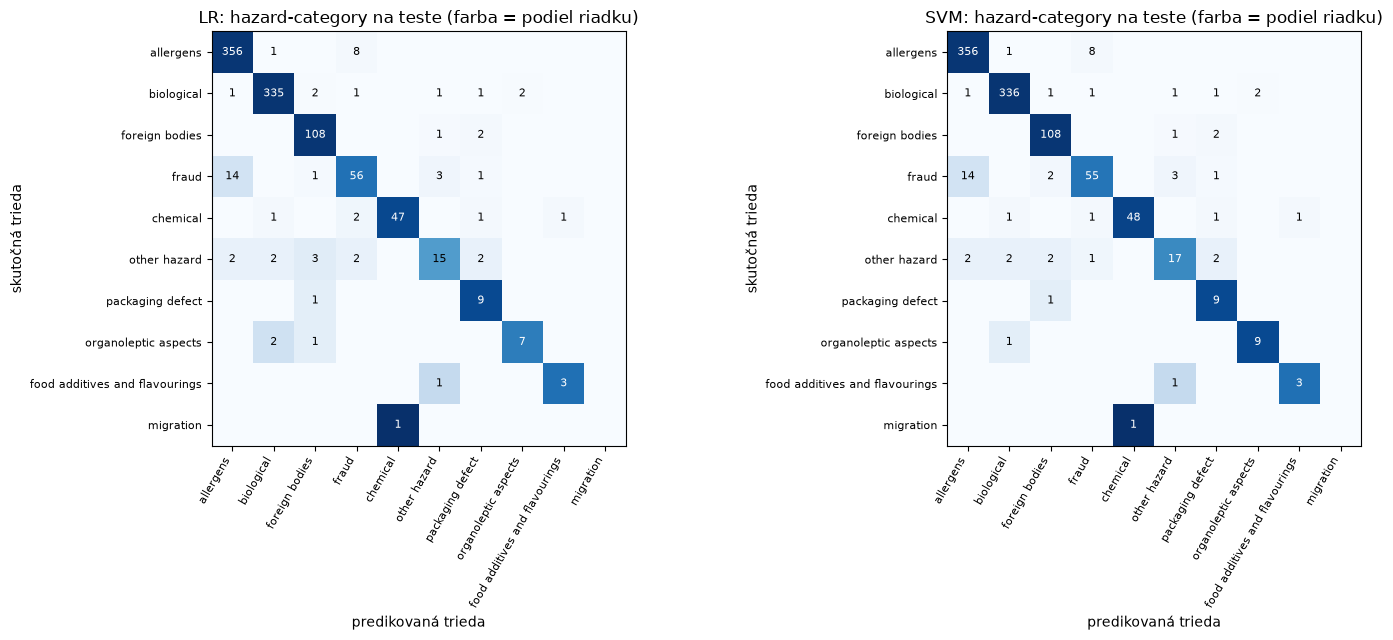

In [15]:
triedy = train["hazard-category"].value_counts().index.tolist()
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, meno in zip(axs, ["LR", "SVM"]):
    cm = confusion_matrix(test["hazard-category"], pred[meno]["hazard-category"], labels=triedy)
    norm_cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(norm_cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(triedy)):
        for j in range(len(triedy)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if norm_cm[i, j] > 0.6 else "black")
    ax.set_xticks(range(len(triedy))); ax.set_xticklabels(triedy, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(triedy))); ax.set_yticklabels(triedy, fontsize=8)
    ax.set_xlabel("predikovaná trieda"); ax.set_ylabel("skutočná trieda")
    ax.set_title(f"{meno}: hazard-category na teste (farba = podiel riadku)")
plt.tight_layout(); plt.savefig(os.path.join(OBRAZKY, "matica_zamen_hazard_category.png"), dpi=150); plt.show()

### 4.2 Najčastejšie zamieňané dvojice tried

In [16]:
def zamieny(lab, meno, n=8):
    d = pd.DataFrame({"skutočná": test[lab], "predikovaná": pred[meno][lab]})
    d = d[d["skutočná"] != d["predikovaná"]]
    return d.value_counts().head(n).rename("počet").reset_index()

for lab in ["hazard-category", "product-category"]:
    for meno in ["LR", "SVM"]:
        z = zamieny(lab, meno)
        print(f"\n{lab} – {meno} (chýb spolu: {(test[lab] != pred[meno][lab]).sum()})")
        print(z.to_string(index=False))


hazard-category – LR (chýb spolu: 61)
      skutočná          predikovaná  počet
         fraud            allergens     14
     allergens                fraud      8
  other hazard       foreign bodies      3
         fraud         other hazard      3
    biological       foreign bodies      2
  other hazard            allergens      2
    biological organoleptic aspects      2
foreign bodies     packaging defect      2

hazard-category – SVM (chýb spolu: 56)
      skutočná          predikovaná  počet
         fraud            allergens     14
     allergens                fraud      8
         fraud         other hazard      3
         fraud       foreign bodies      2
  other hazard            allergens      2
    biological organoleptic aspects      2
foreign bodies     packaging defect      2
  other hazard     packaging defect      2

product-category – LR (chýb spolu: 226)
                    skutočná                  predikovaná  počet
  prepared dishes and snacks meat, egg an

### 4.3 Ukážky chýb na okomentovanie
Náhodne vyberieme 20 testovacích hlásení, kde LR urobila chybu v `hazard-category` alebo `product-category` (10 a 10). Tabuľka sa uloží do `results/chyby_na_komentar.csv`; stĺpec **dôvod** dopĺňa tím ručne po prečítaní celého hlásenia (`id` je poradie riadku v `data/incidents_test.csv`, číslované od 0).

Ak súbor už existuje, ručne napísané dôvody sa pri novom spustení **zachovajú** (spájajú sa podľa `id`), takže notebook sa dá kedykoľvek spustiť znova.

In [17]:
p = pred["LR"]
zlo_h = np.where(test["hazard-category"].values != p["hazard-category"])[0]
zlo_p = np.where((test["product-category"].values != p["product-category"]) &
                 (test["hazard-category"].values == p["hazard-category"]))[0]
rng = np.random.default_rng(SEED)
vyber = list(rng.choice(zlo_h, min(10, len(zlo_h)), replace=False)) + list(rng.choice(zlo_p, min(10, len(zlo_p)), replace=False))

chyby = pd.DataFrame({
    "id": vyber,
    "typ chyby": ["hazard-category"] * min(10, len(zlo_h)) + ["product-category"] * min(10, len(zlo_p)),
    "titulok": test["title"].values[vyber],
    "začiatok textu": test["text"].str.replace(r"\s+", " ", regex=True).str[:200].values[vyber],
    "skutočná hazard-category": test["hazard-category"].values[vyber],
    "predikovaná hazard-category": p["hazard-category"][vyber],
    "skutočný hazard": test["hazard"].values[vyber],
    "skutočná product-category": test["product-category"].values[vyber],
    "predikovaná product-category": p["product-category"][vyber],
    "skutočný product": test["product"].values[vyber],
    "dôvod": "",
})

subor = os.path.join(VYSLEDKY, "chyby_na_komentar.csv")
if os.path.exists(subor):                          # zachovať ručne napísané dôvody
    stare = pd.read_csv(subor, dtype={"dôvod": str}, keep_default_na=False).set_index("id")["dôvod"]
    chyby["dôvod"] = chyby["id"].map(stare).fillna("")
    print(f"vyplnených dôvodov zo súboru: {(chyby['dôvod'] != '').sum()} z {len(chyby)}")
chyby.to_csv(subor, index=False)
chyby.drop(columns=["začiatok textu"])

,id,typ chyby,titulok,skutočná hazard-category,predikovaná hazard-category,skutočný hazard,skutočná product-category,predikovaná product-category,skutočný product,dôvod
0,893,hazard-category,Farm Boy brand Gluten Free Fresh Spinach & Ricotta Ravioli recalled due to u...,fraud,allergens,product category/characteristics,prepared dishes and snacks,cereals and bakery products,ravioli,
1,556,hazard-category,Kailis Bros Pty Ltd — Seafood Salad,allergens,fraud,soybeans and products thereof,seafood,prepared dishes and snacks,seafood,
2,26,hazard-category,"All About Bread—Amaizing Cake Mix, 500g",fraud,allergens,labelling/misdescription,cereals and bakery products,cereals and bakery products,cakes,
3,512,hazard-category,Lidl recalls Favorina Dip Eggs as allergenic ingredients are not declared in...,fraud,allergens,incorrect labeling,"cocoa and cocoa preparations, coffee and tea",cereals and bakery products,chocolate eggs,
4,362,hazard-category,"Kabob's Acquisition, Inc. Recalls Not Ready-To-Eat Meat and Poultry Products...",allergens,biological,cashew,"meat, egg and dairy products","meat, egg and dairy products",poultry meat and poultry meat products,
5,820,hazard-category,Gelsius brand IQF Sliced White Apples and IQF Diced Apples recalled due to u...,fraud,allergens,sulphates/sulphites,fruits and vegetables,fruits and vegetables,apples,
6,963,hazard-category,Garden Fortune Cookies,migration,chemical,other,cereals and bakery products,cereals and bakery products,cookies,
7,37,hazard-category,Buontempo Enterprises—Orgran Fruit Bar No Added Cane Sugar,allergens,fraud,sulphur dioxide and sulphites,cereals and bakery products,cereals and bakery products,fruit bars,
8,105,hazard-category,P & B (Foods) Ltd recalls all batches of Heera Milk Powder due to repackagin...,other hazard,allergens,improper conditions,"meat, egg and dairy products",herbs and spices,milk powder,
9,746,hazard-category,John West recalls Sardines in Tomato Sauce because of suspected bacterial co...,biological,packaging defect,other not classified biological hazards,seafood,"soups, broths, sauces and condiments",sardines,


### 4.4 ST2: výkon podľa početnosti triedy v train
Testovacie hlásenia rozdelíme podľa toho, koľko príkladov má ich skutočná trieda v trénovacích dátach. Pre každú skupinu uvádzame podiel správne predikovaných hlásení (accuracy) a macro-F1 cez triedy skupiny. Počíta sa na všetkých testovacích hláseniach (bez masky oficiálnej metriky), aby sa dalo porovnať hazard a product.

In [18]:
SKUPINY = [(0, 0, "0 (nevidená)"), (1, 4, "1–4"), (5, 20, "5–20"), (21, 10**9, "viac ako 20")]

def podla_pocetnosti(lab):
    pocty = train[lab].value_counts()
    n_train = test[lab].map(pocty).fillna(0).astype(int).values
    riadky = []
    for lo, hi, nazov in SKUPINY:
        m = (n_train >= lo) & (n_train <= hi)
        if m.sum() == 0:
            continue
        triedy_sk = sorted(set(test[lab].values[m]))
        r = {"label": lab, "príkladov triedy v train": nazov, "hlásení v teste": int(m.sum()), "tried": len(triedy_sk)}
        for meno in ["LR", "SVM"]:
            r[f"{meno} accuracy"] = (pred[meno][lab][m] == test[lab].values[m]).mean()
            r[f"{meno} macro-F1"] = f1_score(test[lab].values, pred[meno][lab], labels=triedy_sk, average="macro")
        riadky.append(r)
    return riadky

pocetnost = pd.DataFrame(podla_pocetnosti("hazard") + podla_pocetnosti("product"))
pocetnost.round(3)

,label,príkladov triedy v train,hlásení v teste,tried,LR accuracy,LR macro-F1,SVM accuracy,SVM macro-F1
0,hazard,1–4,24,24,0.292,0.278,0.417,0.396
1,hazard,5–20,92,47,0.554,0.560,0.620,0.589
2,hazard,viac ako 20,881,39,0.876,0.734,0.840,0.712
3,product,0 (nevidená),84,82,0.000,0.000,0.000,0.000
4,product,1–4,218,174,0.261,0.273,0.376,0.336
5,product,5–20,307,142,0.450,0.388,0.485,0.438
6,product,viac ako 20,388,49,0.709,0.576,0.492,0.526


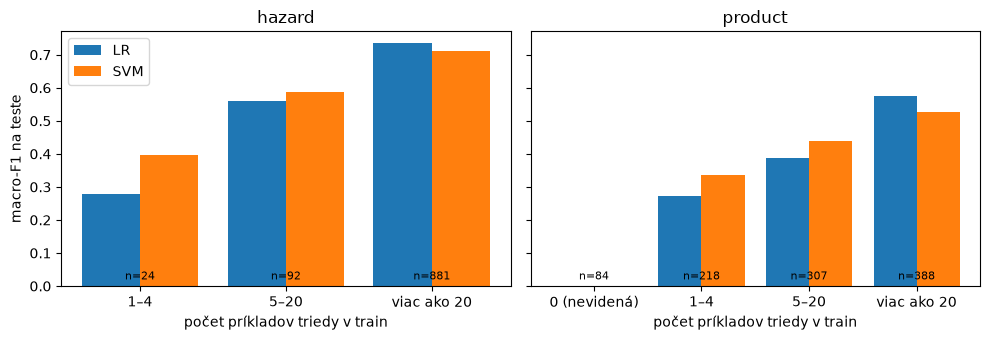

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, lab in zip(axs, ["hazard", "product"]):
    d = pocetnost[pocetnost.label == lab]
    x = np.arange(len(d))
    ax.bar(x - 0.2, d["LR macro-F1"], 0.4, label="LR")
    ax.bar(x + 0.2, d["SVM macro-F1"], 0.4, label="SVM")
    ax.set_xticks(x); ax.set_xticklabels(d["príkladov triedy v train"])
    for i, n in enumerate(d["hlásení v teste"]):
        ax.text(i, 0.02, f"n={n}", ha="center", fontsize=8)
    ax.set_title(lab); ax.set_xlabel("počet príkladov triedy v train")
axs[0].set_ylabel("macro-F1 na teste"); axs[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(OBRAZKY, "st2_podla_pocetnosti.png"), dpi=150); plt.show()

### 4.5 Triedy z testu, ktoré v train vôbec nie sú
Takúto triedu lineárny klasifikátor nemôže predikovať nikdy, lebo ju pozná iba z trénovacích dát.

In [20]:
for lab in LABELY:
    v_train = set(train[lab])
    nove = test.loc[~test[lab].isin(v_train), lab]
    print(f"{lab:18s} tried v teste: {test[lab].nunique():4d}   nevidených tried: {nove.nunique():4d}   "
          f"zasiahnutých hlásení: {len(nove):4d} ({len(nove) / len(test):.1%})")

hazard-category    tried v teste:   10   nevidených tried:    0   zasiahnutých hlásení:    0 (0.0%)
product-category   tried v teste:   20   nevidených tried:    0   zasiahnutých hlásení:    0 (0.0%)
hazard             tried v teste:  110   nevidených tried:    0   zasiahnutých hlásení:    0 (0.0%)
product            tried v teste:  447   nevidených tried:   82   zasiahnutých hlásení:   84 (8.4%)


### 4.6 Chyby v presnom labeli pri správnej kategórii
Ak model zle určí presný produkt, ale kategóriu má správne, chyba je „blízka“. Vysoký podiel takých chýb je argument pre hierarchickú predikciu v 2. etape (najprv kategória, potom presný label iba v rámci nej). Kontrolujeme aj **konzistentnosť**: či predikovaný presný label patrí (podľa train) do predikovanej kategórie.

In [21]:
kat_z_train = {"product": train.groupby("product")["product-category"].agg(lambda s: s.mode()[0]),
               "hazard": train.groupby("hazard")["hazard-category"].agg(lambda s: s.mode()[0])}
riadky = []
for jemny, hruby in [("product", "product-category"), ("hazard", "hazard-category")]:
    for meno in ["LR", "SVM"]:
        p = pred[meno]
        zle = p[jemny] != test[jemny].values
        kat_ok = p[hruby] == test[hruby].values
        kat_predik_jemneho = pd.Series(p[jemny]).map(kat_z_train[jemny]).values
        riadky.append({"label": jemny, "model": meno,
                       "chýb v presnom labeli": int(zle.sum()),
                       "z toho so správnou kategóriou": f"{(zle & kat_ok).sum()} ({(zle & kat_ok).sum() / zle.sum():.0%})",
                       "presný label patrí do predikovanej kategórie": f"{(kat_predik_jemneho == p[hruby]).mean():.0%}"})
pd.DataFrame(riadky)

,label,model,chýb v presnom labeli,z toho so správnou kategóriou,presný label patrí do predikovanej kategórie
0,product,LR,527,336 (64%),82%
1,product,SVM,575,391 (68%),73%
2,hazard,LR,167,121 (72%),95%
3,hazard,SVM,190,144 (76%),95%


## 5. Bootstrap: 95 % intervaly spoľahlivosti
Z testovacej množiny 1 000-krát náhodne vyberieme 997 hlásení s opakovaním a zakaždým vypočítame oficiálne skóre oboch modelov. 2,5. a 97,5. percentil dávajú 95 % interval. Pre rozdiel SVM − LR používame **tie isté** výbery pre oba modely (párové porovnanie): ak interval rozdielu obsahuje nulu, rozdiel medzi modelmi nie je preukázateľný.

In [22]:
B = 1000
rng = np.random.default_rng(SEED)
y = {lab: test[lab].values for lab in LABELY}
vysl = {(m, st): [] for m in ["SVM", "LR"] for st in ["ST1", "ST2"]}
t = time.time()
for _ in range(B):
    i = rng.integers(0, len(test), len(test))
    for m in ["SVM", "LR"]:
        p = pred[m]
        vysl[(m, "ST1")].append(oficialne_skore(y["hazard-category"][i], y["product-category"][i],
                                                p["hazard-category"][i], p["product-category"][i]))
        vysl[(m, "ST2")].append(oficialne_skore(y["hazard"][i], y["product"][i], p["hazard"][i], p["product"][i]))
print(f"bootstrap: {time.time() - t:.0f} s")

# bodový odhad = skóre na celej testovacej množine, v zátvorke 95 % percentilový interval z bootstrapu
def interval(bod, a):
    return f"{bod:.3f}  [{np.percentile(a, 2.5):.3f}; {np.percentile(a, 97.5):.3f}]"

riadky = []
for st in ["ST1", "ST2"]:
    rozdiel = np.array(vysl[("SVM", st)]) - np.array(vysl[("LR", st)])
    riadky.append({"podúloha": st, "SVM": interval(tab["SVM"][st], vysl[("SVM", st)]),
                   "LR": interval(tab["LR"][st], vysl[("LR", st)]),
                   "rozdiel SVM − LR": interval(tab["SVM"][st] - tab["LR"][st], rozdiel),
                   "podiel výberov, kde SVM > LR": f"{(rozdiel > 0).mean():.0%}"})
bootstrap = pd.DataFrame(riadky)
bootstrap.to_csv(os.path.join(VYSLEDKY, "bootstrap.csv"), index=False)
bootstrap

bootstrap: 48 s


,podúloha,SVM,LR,rozdiel SVM − LR,"podiel výberov, kde SVM > LR"
0,ST1,0.723 [0.680; 0.791],0.717 [0.674; 0.793],0.006 [-0.022; 0.022],63%
1,ST2,0.410 [0.384; 0.436],0.406 [0.392; 0.444],0.003 [-0.027; 0.011],19%


Prvé číslo je skóre na celej testovacej množine, v zátvorke je 95 % interval. Priemer bootstrapových výberov by bol o niečo vyšší ako bodový odhad, lebo macro-F1 pri výbere s opakovaním vynecháva časť zriedkavých tried, preto ho neuvádzame.

## 6. Zhrnutie

**Dáta**
- Všetky čísla z tabuľky v sekcii 4 správy sedia: *migration* 3 príklady, *sugars and syrups* 5, 458 produktov s jediným príkladom, 777 produktov a 42 hazardov s menej ako 5 príkladmi. Pri `hazard` má minimum 3 príklady až 27 tried.
- Dve najväčšie triedy `hazard-category` tvoria 70,7 % dát, štyri najmenšie 2,6 %. Model „vždy *allergens*“ by mal accuracy 36,6 % na teste.
- Hlásenia sú z 9 krajín (USA 43 %, Austrália 18 %, Kanada 17 %, UK 14 %) z rokov 1994–2022. Rozdelenie rizík sa podľa krajiny líši (v UK je 54 % alergénov, v Kanade 47 % biologických rizík).
- Únik medzi množinami je zanedbateľný: iba 7 testovacích hlásení (0,7 %) má rovnaký text ako niektoré trénovacie.
- Titulky typu „Recall Notification: FSIS-…“ sú len 0,7 % dát. Nevysvetľujú teda, prečo pomáha pridať text; dôvodom je skôr to, že titulok často nemenuje riziko (napr. „Kailis Bros Pty Ltd — Seafood Salad“).

**Chyby v ST1**
- Najčastejšia zámena je **fraud ↔ allergens**: 22 zo 61 chýb LR (36 %) a 22 z 56 chýb SVM. Ukážky naznačujú, že hranica závisí od anotačnej konvencie: nedeklarovaný lepok v produkte označenom „Gluten Free“ alebo alergény neuvedené po anglicky sú anotované ako *fraud*, hoci text hovorí o alergénoch.
- Pri `product-category` sa najviac mýli trieda *prepared dishes and snacks*, ktorá sa obsahovo prekrýva s mäsom, pečivom aj zeleninou.

**Chyby v ST2**
- Výkon klesá s počtom trénovacích príkladov triedy. Pri produktoch s 1–4 príkladmi je macro-F1 0,27–0,34, pri produktoch s viac ako 20 príkladmi 0,53–0,58.
- 82 produktov z testu (84 hlásení, 8,4 %) sa v train vôbec nenachádza, takže ich baseline nemôže trafiť nikdy. Pri `hazard` žiadna nevidená trieda nie je.
- 64–68 % chýb v produkte a 72–76 % chýb v hazarde má správnu kategóriu. Navyše 18–27 % predikovaných produktov nepatrí do predikovanej kategórie, lebo labely sa predikujú nezávisle. To je argument pre hierarchickú predikciu v 2. etape.

**Spoľahlivosť výsledkov**
- 95 % interval pre ST1 je široký asi 0,11 (napr. SVM 0,723 [0,680; 0,791]).
- Interval rozdielu SVM − LR obsahuje nulu v ST1 aj ST2, takže **rozdiel medzi SVM a LR nie je preukázateľný**. V správe by sa nemal jeden z nich označovať za lepší.